In [1]:
# Uncomment this line if packages are missing.
#%pip install requests numpy pandas matplotlib xmltodict folium pillow imageio-ffmpeg m3u8 ultralytics tqdm

  Using cached xmltodict-1.0.4-py3-none-any.whl.metadata (14 kB)
  Using cached imageio_ffmpeg-0.6.0-py3-none-manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached m3u8-6.0.0-py3-none-any.whl.metadata (4.9 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached torch-2.14.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (37 kB)
  Using cached torchvision-0.29.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (5.7 kB)
  Using cached polars-2.0.0-py3-none-any.whl.metadata (11 kB)
  Using cached nvidia_ml_py-13.615.71-py3-none-any.whl.metadata (9.7 kB)
  Using cached ultralytics_thop-2.2.2-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.90-py3-none-any.whl.metadata (17 kB)
  Using cached polars_runtime_32-2.0.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.5 kB)
  Using cached cuda_toolkit-13.0.3.0-py2.py3-none-any.whl.metadata (17 kB)
  Using cached cuda_bindings-13.4.4-cp313-cp313-

In [1]:
from io import BytesIO
from pathlib import Path
import tempfile
import threading
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import xmltodict
import folium
import m3u8
import imageio_ffmpeg
from PIL import Image, ImageDraw
from ultralytics import YOLO
from tqdm.auto import tqdm
from IPython.display import display, Video

HEADERS = {"User-Agent": "Mozilla/5.0", "Referer": "https://511.vdot.virginia.gov/"}
OUTPUT_DIR = Path("trafficcheck_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [2]:
SENSOR_URL = 'https://data.511-atis-ttrip-prod.iteriscloud.com/smarterRoads/trafficSensor/detectorTMDD/current/trafficSensor_tmdd.xml?token=%242b%2410%24N%2FYVSDe.cOJFuEhCXEV4UuZogMpl7P.0s34ySk%2Fx40HfYIxI.CpH6'
CAMERA_URL = "https://511.vdot.virginia.gov/services/511/map/layers/map/cams"
WEST, SOUTH, EAST, NORTH = -77.5940, 37.8982, -77.4026, 38.3724


def as_list(value):
    return value if isinstance(value, list) else ([] if value is None else [value])


def get_stations():
    response = requests.get(SENSOR_URL, timeout=20)
    response.raise_for_status()
    parsed = xmltodict.parse(response.content, process_namespaces=True, namespaces={
        "http://www.openroadsconsulting.org/detector": None,
        "http://www.qfree.com/common": None,
    })
    return as_list(parsed["stationList"]["station"])


def direction_label(value):
    return {"n": "NB", "s": "SB", "e": "EB", "w": "WB"}.get(
        str(value).lower(), str(value or "Unknown").upper()
    )


stations = get_stations()
station_by_id = {}
station_rows = []
for station in stations:
    inventory = station["inventory"]
    header = inventory["detector-station-inventory-header"]
    station_by_id[header["device-id"]] = station
    directions = {
        direction_label(detector["detector-inventory-header"].get("link-direction"))
        for detector in as_list(inventory["detector-list"].get("detector"))
    }
    station_rows.append({
        "id": header["device-id"], "name": header.get("device-name"),
        "route": header.get("link-name"), "direction": " / ".join(sorted(directions)),
        "latitude": float(header["device-location"]["latitude"]) / 1e6,
        "longitude": float(header["device-location"]["longitude"]) / 1e6,
    })
station_df = pd.DataFrame(station_rows)

response = requests.get(CAMERA_URL, headers=HEADERS, timeout=30)
response.raise_for_status()
camera_df = pd.DataFrame([
    dict(feature["properties"], longitude=feature["geometry"]["coordinates"][0],
         latitude=feature["geometry"]["coordinates"][1])
    for feature in response.json()["features"]
])
camera_df["id"] = camera_df["id"].astype(str)

station_df = station_df[
    station_df.longitude.between(WEST, EAST) & station_df.latitude.between(SOUTH, NORTH)
].copy()
camera_df = camera_df[
    camera_df.longitude.between(WEST, EAST) & camera_df.latitude.between(SOUTH, NORTH)
].copy()
print(f"Study area: {len(station_df)} sensor sites and {len(camera_df)} cameras")

Study area: 27 sensor sites and 39 cameras


In [3]:
def map_devices(cameras, sensors):
    map_view = folium.Map(location=[38.291, -77.507], zoom_start=11, control_scale=True)
    for table, label, color in [(cameras, "Cameras", "orange"), (sensors, "Sensors", "blue")]:
        group = folium.FeatureGroup(name=label)
        for _, row in table.iterrows():
            name = row.get("description", row.get("name", ""))
            folium.CircleMarker(
                [row.latitude, row.longitude], radius=6, color=color,
                fill=True, fill_opacity=0.8,
                tooltip=f"{row['id']} | {row.get('direction', 'Unknown')}",
                popup=f"{row['id']} | {name} | {row.get('direction', 'Unknown')}",
            ).add_to(group)
        group.add_to(map_view)
    points = pd.concat([cameras, sensors])[["latitude", "longitude"]]
    if len(points) > 1:
        map_view.fit_bounds(points.values.tolist(), padding=(25, 25))
    folium.LayerControl().add_to(map_view)
    return map_view


display(map_devices(camera_df, station_df))

,id,description,direction,latitude,longitude
128,2025,VA-3 / MM 31.6 / EB,EB,38.295760,-77.512100
145,1869,I-95 / MM 132.1 / SB,SB,38.321161,-77.504327
146,592,I-95 / MM 129 / NB,NB,38.276900,-77.511870
149,1729,I-95 / MM 133.6 / SB,SB,38.340980,-77.491910
153,2141,I-95 / MM 120.1 / NB,NB,38.153360,-77.506400


,station_id,detector_id,name,direction,interval_start,interval_end,sample_seconds,vehicle_count,occupancy,speed
0,OpenTMS-Detector228909067,OpenTMS-Detector228909067-1,NB Right Lane,NB,2022-08-16 14:10:00+00:00,2022-08-16 14:15:00+00:00,300,0,0,0
1,OpenTMS-Detector228909067,OpenTMS-Detector228909067-2,NB Middle lane,NB,2022-08-16 14:10:00+00:00,2022-08-16 14:15:00+00:00,300,0,0,0
2,OpenTMS-Detector228909067,OpenTMS-Detector228909067-3,NB Left Lane,NB,2022-08-16 14:10:00+00:00,2022-08-16 14:15:00+00:00,300,0,0,0
3,OpenTMS-Detector400141,OpenTMS-Detector400141-1,On Ramp from Rest Area,NB,2026-10-19 13:00:00+00:00,2026-10-19 13:05:00+00:00,300,4,0,45
4,OpenTMS-Detector400141,OpenTMS-Detector400141-2,NB Right Lane,NB,2026-10-19 13:00:00+00:00,2026-10-19 13:05:00+00:00,300,49,7,72


Example camera: 592 I-95 / MM 129 / NB


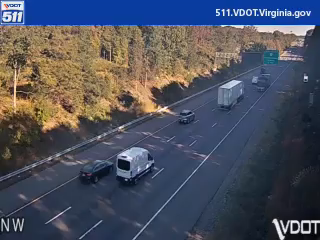

In [4]:
def sensor_readings(station_list):
    rows = []
    for station in station_list:
        inventory = station["inventory"]
        station_id = inventory["detector-station-inventory-header"]["device-id"]
        detector_info = {
            detector["detector-inventory-header"]["device-id"]: detector["detector-inventory-header"]
            for detector in as_list(inventory["detector-list"].get("detector"))
        }
        for data in as_list(station.get("data", {}).get("detector-list", {}).get("detector-data-detail")):
            info = detector_info.get(data["detector-id"], {})
            def timestamp(field):
                value = data.get(field, {}).get("dateTimeHolder", {}).get("iso-8601")
                return pd.to_datetime(value, utc=True, errors="coerce")
            rows.append({
                "station_id": station_id, "detector_id": data["detector-id"],
                "name": info.get("device-name"), "direction": direction_label(info.get("link-direction")),
                "interval_start": timestamp("start-time"), "interval_end": timestamp("end-time"),
                "sample_seconds": pd.to_numeric(data.get("sample-period"), errors="coerce"),
                "vehicle_count": pd.to_numeric(data.get("vehicle-count"), errors="coerce"),
                "occupancy": pd.to_numeric(data.get("vehicle-occupancy"), errors="coerce"),
                "speed": pd.to_numeric(data.get("vehicle-speed"), errors="coerce"),
            })
    return pd.DataFrame(rows)


def get_snapshot(camera_row):
    response = requests.get(camera_row["image_url"], headers=HEADERS, timeout=20)
    response.raise_for_status()
    return np.asarray(Image.open(BytesIO(response.content)).convert("RGB"))


area_stations = [station_by_id[station_id] for station_id in station_df.id]
sensor_df = sensor_readings(area_stations)
display(camera_df[["id", "description", "direction", "latitude", "longitude"]].head())
display(sensor_df.head())
example_camera = camera_df.loc[(camera_df.route == "I-95") & (camera_df.direction == "NB")].iloc[0]
print("Example camera:", example_camera['id'], example_camera['description'])
display(Image.fromarray(get_snapshot(example_camera)))

## 5. Use the devices we chose
Keep all three NB cameras on the selection map. Camera **4363** supplies the video for the remaining cells. Use only the sensor's NB mainline lanes in the comparison; its off-ramp detector stays separate.

In [5]:
CAMERA_IDS = ["4363", "4364", "4365"]
CAMERA_ID = "4363"
SENSOR_ID = "OpenTMS-Detector4941987957"

chosen_cameras = camera_df.set_index("id").loc[CAMERA_IDS].reset_index()
chosen_sensor = station_df.loc[station_df.id == SENSOR_ID]
if chosen_sensor.empty:
    raise ValueError("Selected sensor is missing from the study-area inventory.")
if not chosen_cameras.direction.eq("NB").all():
    raise ValueError("One of the selected cameras is no longer labeled NB.")
camera = chosen_cameras.loc[chosen_cameras.id == CAMERA_ID].iloc[0]
selected_station = station_by_id[SENSOR_ID]
mainline_ids = {
    detector["detector-inventory-header"]["device-id"]
    for detector in as_list(selected_station["inventory"]["detector-list"]["detector"])
    if direction_label(detector["detector-inventory-header"].get("link-direction")) == "NB"
    and str(detector["detector-inventory-header"].get("device-name", "")).lower().startswith("lane")
}
if not mainline_ids:
    raise ValueError("No NB mainline lane detectors were found for the selected sensor.")

display(chosen_cameras[["id", "description", "direction", "latitude", "longitude"]])
display(chosen_sensor)
display(sensor_readings([selected_station]))
print(f"Comparison uses camera {CAMERA_ID} and {len(mainline_ids)} NB sensor lanes.")
display(map_devices(chosen_cameras, chosen_sensor))

,id,description,direction,latitude,longitude
0,4363,I-95 / MM 130.0 / NB,NB,38.291163,-77.506823
1,4364,I-95 / MM 130.0 / NB 2,NB,38.291168,-77.506923
2,4365,I-95 / MM 130.0 / NB 3,NB,38.291173,-77.507023


,id,name,route,direction,latitude,longitude
345,OpenTMS-Detector4941987957,NRO-TSS-I95-N-01299,I-95N,NB,38.290683,-77.507003


,station_id,detector_id,name,direction,interval_start,interval_end,sample_seconds,vehicle_count,occupancy,speed
0,OpenTMS-Detector4941987957,OpenTMS-Detector4941987957-0,Off Ramp,NB,2026-10-19 13:10:00+00:00,2026-10-19 13:15:00+00:00,300,14,1,66
1,OpenTMS-Detector4941987957,OpenTMS-Detector4941987957-1,Lane1,NB,2026-10-19 13:10:00+00:00,2026-10-19 13:15:00+00:00,300,90,11,65
2,OpenTMS-Detector4941987957,OpenTMS-Detector4941987957-2,Lane2,NB,2026-10-19 13:10:00+00:00,2026-10-19 13:15:00+00:00,300,104,11,70
3,OpenTMS-Detector4941987957,OpenTMS-Detector4941987957-3,Lane3,NB,2026-10-19 13:10:00+00:00,2026-10-19 13:15:00+00:00,300,93,9,73


Comparison uses camera 4363 and 3 NB sensor lanes.


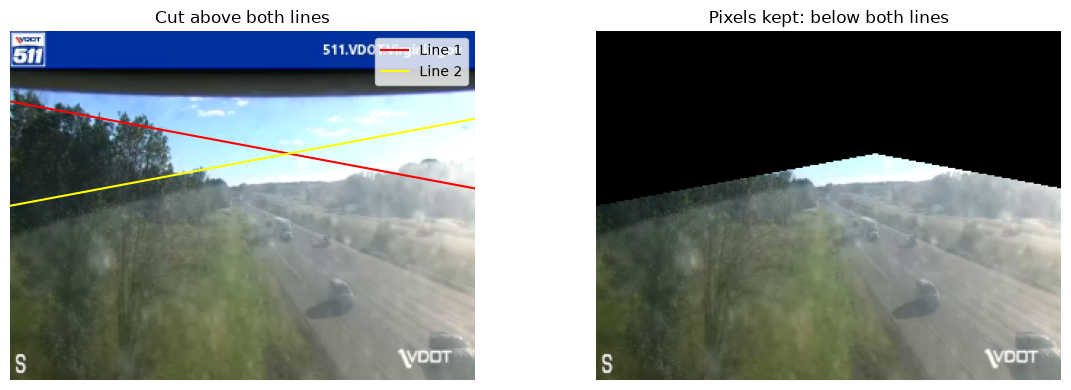

In [12]:
# Each line is specified by where it meets the left and right edges (fractions down from the top).
LINE_1_LEFT_Y = 0.20
LINE_1_RIGHT_Y = 0.45
LINE_2_LEFT_Y = 0.50
LINE_2_RIGHT_Y = 0.25


def crop_below_lines(frame_rgb):
    """Black out everything above either line; retain pixels below both."""
    height, width = frame_rgb.shape[:2]
    x_fraction = np.linspace(0, 1, width)
    first_line = LINE_1_LEFT_Y + (LINE_1_RIGHT_Y - LINE_1_LEFT_Y) * x_fraction
    second_line = LINE_2_LEFT_Y + (LINE_2_RIGHT_Y - LINE_2_LEFT_Y) * x_fraction
    cutoff_y = np.maximum(first_line, second_line) * (height - 1)
    keep = np.arange(height)[:, None] >= cutoff_y[None, :]
    cropped = frame_rgb.copy()
    cropped[~keep] = 0
    return cropped


frame = get_snapshot(camera)
height, width = frame.shape[:2]
x_pixels = [0, width - 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(frame)
axes[0].plot(x_pixels, [LINE_1_LEFT_Y * (height - 1), LINE_1_RIGHT_Y * (height - 1)], color="red", label="Line 1")
axes[0].plot(x_pixels, [LINE_2_LEFT_Y * (height - 1), LINE_2_RIGHT_Y * (height - 1)], color="yellow", label="Line 2")
axes[0].set_title("Cut above both lines")
axes[0].legend()
axes[1].imshow(crop_below_lines(frame))
axes[1].set_title("Pixels kept: below both lines")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
#helper functions to get video

In [13]:
def get_playlist(url):
    response = requests.get(url, headers=HEADERS, timeout=15)
    response.raise_for_status()
    if not response.text.lstrip().startswith("#EXTM3U"):
        raise ValueError("Camera endpoint did not return an HLS playlist.")
    return m3u8.loads(response.text, uri=response.url)


def capture_video(seconds):
    url = camera["https_url"]
    playlist = get_playlist(url)
    if playlist.is_variant:
        variant = max(playlist.playlists, key=lambda p: p.stream_info.bandwidth)
        url = variant.absolute_uri
        playlist = get_playlist(url)
    seen = {segment.absolute_uri for segment in playlist.segments}
    captured, errors = [], []
    last_end, last_sequence = None, None
    started = time.monotonic()
    with tqdm(total=seconds, desc="Capturing live video", unit="s") as progress:
        while time.monotonic() - started < seconds:
            try:
                playlist = get_playlist(url)
                for index, segment in enumerate(playlist.segments):
                    if segment.absolute_uri in seen:
                        continue
                    response = requests.get(segment.absolute_uri, headers=HEADERS, timeout=15)
                    response.raise_for_status()
                    sequence = playlist.media_sequence + index
                    source_time = segment.program_date_time or segment.current_program_date_time
                    if source_time is not None:
                        start = pd.Timestamp(source_time).tz_convert("UTC")
                    elif last_end is not None and sequence == last_sequence + 1:
                        start = last_end
                    else:
                        remaining = sum(s.duration for s in playlist.segments[index:])
                        start = pd.Timestamp.now(tz="UTC") - pd.Timedelta(seconds=remaining)
                    captured.append({"bytes": response.content, "start": start,
                                     "duration": segment.duration, "estimated_time": source_time is None})
                    seen.add(segment.absolute_uri)
                    last_end = start + pd.Timedelta(seconds=segment.duration)
                    last_sequence = sequence
            except requests.RequestException as exc:
                errors.append(type(exc).__name__)
            progress.update(min(seconds, time.monotonic() - started) - progress.n)
            time.sleep(1)
        progress.update(seconds - progress.n)
    if not captured:
        raise RuntimeError(f"No video segments arrived. Network errors: {errors[-3:]}")
    if errors:
        print(f"Video requests retried: {len(errors)}; missing frames affect window coverage.")
    return captured


def read_segment(segment):
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "segment.ts"
        path.write_bytes(segment["bytes"])
        reader = imageio_ffmpeg.read_frames(str(path), pix_fmt="rgb24")
        try:
            metadata = next(reader)
            width, height = metadata["size"]
            frames = [np.frombuffer(raw, np.uint8).reshape(height, width, 3) for raw in reader]
        finally:
            reader.close()
    return frames, float(metadata["fps"])


def write_clip(frames, path, fps):
    height, width = frames[0].shape[:2]
    writer = imageio_ffmpeg.write_frames(str(path), size=(width, height), fps=fps,
                                       codec="libx264", pix_fmt_in="rgb24", pix_fmt_out="yuv420p",
                                       macro_block_size=1)
    writer.send(None)
    try:
        for frame in frames:
            writer.send(np.ascontiguousarray(frame).tobytes())
    finally:
        writer.close()

In [ ]:
#sample video collection

In [ ]:
SAMPLE_SECONDS = 10

# This cell creates sample_frames and fps for the YOLO preview cell below.
sample_segments = capture_video(SAMPLE_SECONDS)
sample_frames = []
fps = None
for segment in sample_segments:
    decoded_frames, segment_fps = read_segment(segment)
    fps = segment_fps
    sample_frames.extend(crop_below_lines(frame) for frame in decoded_frames)
    if len(sample_frames) >= round(SAMPLE_SECONDS * fps):
        break

if not sample_frames or fps is None:
    raise RuntimeError("No sample video frames were decoded.")
sample_frames = sample_frames[:round(SAMPLE_SECONDS * fps)]

sample_path = OUTPUT_DIR / f"camera_{CAMERA_ID}_cropped.mp4"
write_clip(sample_frames, sample_path, fps)
print(f"Sample video: {len(sample_frames)} cropped frames at {fps:g} fps")
display(Video(filename=str(sample_path), embed=True, width=640))

Capturing live video:   0%|          | 0/10 [00:00<?, ?s/s]

In [ ]:
#yolo on sample video

In [5]:
CONFIDENCE = 0.05
model = YOLO("yolo11s.pt")
vehicle_ids = [class_id for class_id, name in model.names.items() if name in {"car", "truck"}]
if not vehicle_ids:
    raise ValueError("The model has no car or truck classes.")


def detect_vehicles(frames):
    for index in range(0, len(frames), 16):
        # NumPy inputs to YOLO use BGR; our images and video writer use RGB.
        batch = [frame[:, :, ::-1].copy() for frame in frames[index:index + 16]]
        yield from model.predict(batch, classes=vehicle_ids, conf=CONFIDENCE, imgsz=320, verbose=False)


annotated_frames = []
sample_counts = []
for result in tqdm(detect_vehicles(sample_frames), total=len(sample_frames), desc="Sample YOLO"):
    sample_counts.append(len(result.boxes))
    annotated_frames.append(result.plot()[:, :, ::-1].copy())
yolo_path = OUTPUT_DIR / f"camera_{CAMERA_ID}_cropped_yolo.mp4"
write_clip(annotated_frames, yolo_path, fps)
print(f"Sample mean: {np.mean(sample_counts):.2f} car/truck boxes per frame")
display(Video(filename=str(yolo_path), embed=True, width=640))

NameError: name 'sample_frames' is not defined

In [ ]:
#Data collection

In [ ]:
CAPTURE_MINUTES = 90
SENSOR_POLL_SECONDS = 60

CAPTURE_ID = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%SZ")
RAW_VIDEO_DIR = OUTPUT_DIR / f"camera_{CAMERA_ID}_raw_segments_{CAPTURE_ID}"
RAW_VIDEO_DIR.mkdir(parents=True, exist_ok=True)

sensor_samples, sensor_errors = [], []
stop_sensor = threading.Event()


def poll_sensor():
    while not stop_sensor.is_set():
        try:
            current = next(s for s in get_stations()
                           if s["inventory"]["detector-station-inventory-header"]["device-id"] == SENSOR_ID)
            readings = sensor_readings([current])
            if readings.empty:
                raise ValueError("Selected sensor returned no detector readings.")
            readings["polled_at"] = pd.Timestamp.now(tz="UTC")
            sensor_samples.append(readings)
        except Exception as exc:
            sensor_errors.append(type(exc).__name__)
        stop_sensor.wait(SENSOR_POLL_SECONDS)


sensor_thread = threading.Thread(target=poll_sensor, daemon=True)
sensor_thread.start()
try:
    captured_segments = capture_video(CAPTURE_MINUTES * 60)
finally:
    stop_sensor.set()
    sensor_thread.join(timeout=25)

# Save sensor polls immediately so they remain available even if later video
# decoding or YOLO processing needs to be rerun.
if sensor_samples:
    sensor_polls = pd.concat(sensor_samples, ignore_index=True)
    sensor_polls.to_csv(OUTPUT_DIR / f"sensor_{SENSOR_ID}_raw_polls_{CAPTURE_ID}.csv", index=False)
else:
    raise RuntimeError(f"No sensor readings captured. Errors: {sensor_errors[-3:]}")
if sensor_errors:
    print(f"Sensor poll failures: {len(sensor_errors)}")

# Save each original transport-stream segment and a timestamp manifest for
# future reprocessing with a different crop, model, or aggregation interval.
segment_manifest = []
for segment_number, segment in enumerate(captured_segments):
    segment_path = RAW_VIDEO_DIR / f"segment_{segment_number:06d}.ts"
    segment_path.write_bytes(segment["bytes"])
    segment_manifest.append({
        "segment_number": segment_number,
        "file": segment_path.name,
        "start_utc": segment["start"],
        "duration_seconds": segment["duration"],
        "estimated_time": segment["estimated_time"],
        "bytes": len(segment["bytes"]),
    })
segment_manifest = pd.DataFrame(segment_manifest)
segment_manifest.to_csv(OUTPUT_DIR / f"camera_{CAMERA_ID}_segment_manifest_{CAPTURE_ID}.csv", index=False)

counts = []
for segment in tqdm(captured_segments, desc="YOLO on captured video", unit="segment"):
    frames, source_fps = read_segment(segment)
    cropped = [crop_below_lines(frame) for frame in frames]
    for index, result in enumerate(detect_vehicles(cropped)):
        timestamp = segment["start"] + pd.Timedelta(seconds=(index + 0.5) * segment["duration"] / len(frames))
        counts.append({"time_utc": timestamp, "car_boxes": len(result.boxes)})
frame_counts = pd.DataFrame(counts)
frame_counts.to_csv(OUTPUT_DIR / f"camera_{CAMERA_ID}_raw_frame_counts_{CAPTURE_ID}.csv", index=False)
print(f"Analyzed {len(frame_counts)} frames; collected {sensor_polls.polled_at.nunique()} sensor polls.")
print("Sensor source sample periods (seconds):", sorted(sensor_polls.sample_seconds.dropna().unique()))
print("Saved raw sensor polls:", OUTPUT_DIR / f"sensor_{SENSOR_ID}_raw_polls_{CAPTURE_ID}.csv")
print("Saved raw per-frame YOLO counts:", OUTPUT_DIR / f"camera_{CAMERA_ID}_raw_frame_counts_{CAPTURE_ID}.csv")
print("Saved original video segments:", RAW_VIDEO_DIR)
print("Saved segment timestamps:", OUTPUT_DIR / f"camera_{CAMERA_ID}_segment_manifest_{CAPTURE_ID}.csv")
if any(segment["estimated_time"] for segment in captured_segments):
    print("Camera UTC times are estimated from HLS publication; a small timing offset may remain.")

Capturing live video:   0%|          | 0/5400 [00:00<?, ?s/s]

YOLO on captured video:   0%|          | 0/1080 [00:00<?, ?segment/s]

In [ ]:
#AI to help connect sensor and video

In [3]:
frame_counts["half_second"] = frame_counts.time_utc.dt.floor("500ms")
smoothed = frame_counts.groupby("half_second").car_boxes.median().reset_index(name="median_boxes")
smoothed["window_utc"] = smoothed.half_second.dt.floor("5min")
camera_5min = smoothed.groupby("window_utc").agg(
    mean_of_medians=("median_boxes", "mean"), half_second_bins=("median_boxes", "size")
).reset_index()
camera_5min["video_coverage"] = camera_5min.half_second_bins / 600

# Keep the latest poll for each detector source interval; exclude the off-ramp.
lanes = sensor_polls[sensor_polls.detector_id.isin(mainline_ids)].copy()
lanes = lanes.sort_values("polled_at").drop_duplicates(["detector_id", "interval_start", "interval_end"], keep="last")
lanes = lanes[
    lanes.sample_seconds.eq(300)
    & (lanes.interval_end - lanes.interval_start).dt.total_seconds().eq(300)
    & lanes.interval_start.eq(lanes.interval_start.dt.floor("5min"))
    & lanes.vehicle_count.ge(0)
]
sensor_5min = lanes.groupby("interval_start").agg(
    sensor_vehicles=("vehicle_count", "sum"), lanes_reporting=("detector_id", "nunique")
).reset_index().rename(columns={"interval_start": "window_utc"})

comparison = camera_5min.merge(sensor_5min, on="window_utc", how="left")
comparison.to_csv(OUTPUT_DIR / f"camera_{CAMERA_ID}_sensor_5min.csv", index=False)
display(comparison)
plot_data = comparison[
    comparison.video_coverage.ge(0.90) & comparison.lanes_reporting.eq(len(mainline_ids))
].dropna(subset=["sensor_vehicles"])

if plot_data.empty:
    print("No complete matching five-minute interval yet. Check the table and run a longer capture.")
else:
    local_time = plot_data.window_utc.dt.tz_convert("America/New_York")
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    axes[0].plot(local_time, plot_data.mean_of_medians, "o-", color="tab:orange")
    axes[0].set_ylabel("YOLO cars + trucks visible\nmean of half-second medians")
    axes[1].plot(local_time, plot_data.sensor_vehicles, "o-", color="tab:blue")
    axes[1].set_ylabel("Sensor vehicles\nper five-minute interval")
    axes[1].set_xlabel("Five-minute interval start (America/New_York)")
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=local_time.dt.tz))
    axes[1].set_xlim(local_time.min() - pd.Timedelta(minutes=2.5),
                     local_time.max() + pd.Timedelta(minutes=2.5))
    for ax in axes:
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3)
    fig.suptitle(f"Camera {CAMERA_ID} and NB sensor mainline lanes")
    plt.tight_layout()
    plt.show()
print("Saved comparison:", OUTPUT_DIR / f"camera_{CAMERA_ID}_sensor_5min.csv")

NameError: name 'frame_counts' is not defined

In [ ]:
#Calcing the 5min mean of (1s median) vs 5 min sensor

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# These two CSVs must be in the notebook's current folder.
frames = pd.read_csv("camera_4363_raw_frame_counts_20261015T180649Z.csv")
sensor = pd.read_csv("sensor_OpenTMS-Detector4941987957_raw_polls_20261015T180649Z.csv")

# YOLO: median box count per 1-second bin, then mean per 5-minute window.
frames["time_utc"] = pd.to_datetime(frames["time_utc"], utc=True)
frames["one_second"] = frames["time_utc"].dt.floor("1s")
frames["window_utc"] = frames["one_second"].dt.floor("5min")

camera = (
    frames.groupby(["window_utc", "one_second"])["car_boxes"]
    .median()
    .groupby(level="window_utc")
    .mean()
    .rename("yolo_mean")
    .reset_index()
)

coverage = (
    frames.groupby("window_utc")["one_second"]
    .nunique()
    .div(300)
    .rename("video_coverage")
    .reset_index()
)
camera = camera.merge(coverage, on="window_utc")

# Keep the three NB mainline lanes; exclude the off-ramp.
sensor["interval_start"] = pd.to_datetime(sensor["interval_start"], utc=True)
sensor["interval_end"] = pd.to_datetime(sensor["interval_end"], utc=True)
sensor["polled_at"] = pd.to_datetime(sensor["polled_at"], utc=True)
sensor["occupancy"] = pd.to_numeric(sensor["occupancy"], errors="coerce")
sensor["vehicle_count"] = pd.to_numeric(sensor["vehicle_count"], errors="coerce")

mainline = sensor[
    sensor["direction"].astype(str).str.upper().eq("NB")
    & sensor["name"].astype(str).str.match(r"^Lane\d+$")
    & sensor["sample_seconds"].eq(300)
    & ((sensor["interval_end"] - sensor["interval_start"]).dt.total_seconds() == 300)
].copy()

# Repeated polls may contain the same published interval; keep one per lane.
mainline = mainline.sort_values("polled_at").drop_duplicates(
    ["detector_id", "interval_start", "interval_end"], keep="last"
)

expected_lanes = mainline["detector_id"].nunique()
sensor_5min = (
    mainline.groupby("interval_start")
    .agg(
        sensor_occupancy=("occupancy", "mean"),
        sensor_vehicles=("vehicle_count", "sum"),
        lanes_reporting=("detector_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"interval_start": "window_utc"})
)

comparison = camera.merge(sensor_5min, on="window_utc", how="inner")
matched = comparison[
    comparison["video_coverage"].ge(0.90)
    & comparison["lanes_reporting"].eq(expected_lanes)
].dropna(subset=["yolo_mean", "sensor_occupancy"])

if len(matched) < 2:
    raise ValueError(f"Only {len(matched)} complete matched windows; need at least 2.")

pearson_r = matched["yolo_mean"].corr(matched["sensor_occupancy"])
spearman_r = matched["yolo_mean"].corr(
    matched["sensor_occupancy"], method="spearman"
)

print(f"Matched 5-minute windows: {len(matched)}")
print(f"YOLO vs. sensor occupancy — Pearson r: {pearson_r:.3f}")
print(f"YOLO vs. sensor occupancy — Spearman r: {spearman_r:.3f}")

# Graph 1: compare trends after standardizing both measures.
times = matched["window_utc"].dt.tz_convert("America/New_York")
yolo_z = (matched["yolo_mean"] - matched["yolo_mean"].mean()) / matched["yolo_mean"].std()
occupancy_z = (
    (matched["sensor_occupancy"] - matched["sensor_occupancy"].mean())
    / matched["sensor_occupancy"].std()
)

fig, (trend, scatter) = plt.subplots(1, 2, figsize=(12, 4))

trend.plot(times, yolo_z, "o-", label="YOLO: 1-second medians")
trend.plot(times, occupancy_z, "o-", label="Sensor occupancy")
trend.set_title("Five-minute trends (standardized)")
trend.set_ylabel("Standard deviations from mean")
trend.tick_params(axis="x", rotation=45)
trend.grid(alpha=0.3)
trend.legend()

x = matched["sensor_occupancy"]
y = matched["yolo_mean"]
scatter.scatter(x, y)
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
scatter.plot(x_line, slope * x_line + intercept, color="red")
scatter.set_title(f"YOLO vs. occupancy\nPearson r={pearson_r:.3f}, Spearman r={spearman_r:.3f}")
scatter.set_xlabel("Mean occupancy across NB mainline lanes")
scatter.set_ylabel("YOLO mean of 1-second medians")
scatter.grid(alpha=0.3)

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'camera_4363_raw_frame_counts_20261015T180649Z.csv'

In [ ]:
#CORR of Sensor and YOLO

Matched 5-minute windows: 15
YOLO vs. sensor occupancy — Pearson r: 0.954
YOLO vs. sensor occupancy — Spearman r: 0.962


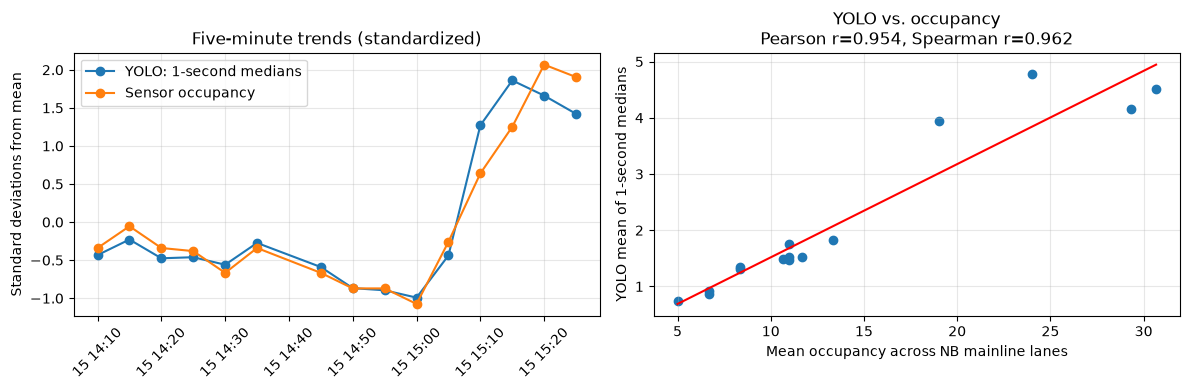

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# This is the folder used by the notebook's capture cell.
OUTPUT_DIR = Path("trafficcheck_outputs")

frames = pd.read_csv(
    OUTPUT_DIR / "camera_4363_raw_frame_counts_20261015T180649Z.csv"
)
sensor = pd.read_csv(
    OUTPUT_DIR / "sensor_OpenTMS-Detector4941987957_raw_polls_20261015T180649Z.csv"
)

# YOLO: median box count per 1-second bin, then mean per 5-minute window.
frames["time_utc"] = pd.to_datetime(frames["time_utc"], utc=True)
frames["one_second"] = frames["time_utc"].dt.floor("1s")
frames["window_utc"] = frames["one_second"].dt.floor("5min")

camera = (
    frames.groupby(["window_utc", "one_second"])["car_boxes"]
    .median()
    .groupby(level="window_utc")
    .mean()
    .rename("yolo_mean")
    .reset_index()
)

coverage = (
    frames.groupby("window_utc")["one_second"]
    .nunique()
    .div(300)
    .rename("video_coverage")
    .reset_index()
)
camera = camera.merge(coverage, on="window_utc")

# Keep NB mainline lanes; this excludes the off-ramp.
sensor["interval_start"] = pd.to_datetime(sensor["interval_start"], utc=True)
sensor["interval_end"] = pd.to_datetime(sensor["interval_end"], utc=True)
sensor["polled_at"] = pd.to_datetime(sensor["polled_at"], utc=True)
sensor["occupancy"] = pd.to_numeric(sensor["occupancy"], errors="coerce")
sensor["vehicle_count"] = pd.to_numeric(sensor["vehicle_count"], errors="coerce")

mainline = sensor[
    sensor["direction"].astype(str).str.upper().eq("NB")
    & sensor["name"].astype(str).str.match(r"^Lane\d+$")
    & sensor["sample_seconds"].eq(300)
    & ((sensor["interval_end"] - sensor["interval_start"]).dt.total_seconds() == 300)
].copy()

# Keep one latest poll per lane and published interval.
mainline = mainline.sort_values("polled_at").drop_duplicates(
    ["detector_id", "interval_start", "interval_end"], keep="last"
)
expected_lanes = mainline["detector_id"].nunique()

sensor_5min = (
    mainline.groupby("interval_start")
    .agg(
        sensor_occupancy=("occupancy", "mean"),
        sensor_vehicles=("vehicle_count", "sum"),
        lanes_reporting=("detector_id", "nunique"),
    )
    .reset_index()
    .rename(columns={"interval_start": "window_utc"})
)

comparison = camera.merge(sensor_5min, on="window_utc", how="inner")
matched = comparison[
    comparison["video_coverage"].ge(0.90)
    & comparison["lanes_reporting"].eq(expected_lanes)
].dropna(subset=["yolo_mean", "sensor_occupancy"])

if len(matched) < 2:
    raise ValueError(f"Only {len(matched)} complete matched windows; need at least 2.")

pearson_r = matched["yolo_mean"].corr(matched["sensor_occupancy"])
spearman_r = matched["yolo_mean"].corr(
    matched["sensor_occupancy"], method="spearman"
)

print(f"Matched 5-minute windows: {len(matched)}")
print(f"YOLO vs. sensor occupancy — Pearson r: {pearson_r:.3f}")
print(f"YOLO vs. sensor occupancy — Spearman r: {spearman_r:.3f}")

# Graph 1: compare standardized trends. Graph 2: scatterplot.
times = matched["window_utc"].dt.tz_convert("America/New_York")
yolo_z = (matched["yolo_mean"] - matched["yolo_mean"].mean()) / matched["yolo_mean"].std()
occupancy_z = (
    (matched["sensor_occupancy"] - matched["sensor_occupancy"].mean())
    / matched["sensor_occupancy"].std()
)

fig, (trend, scatter) = plt.subplots(1, 2, figsize=(12, 4))

trend.plot(times, yolo_z, "o-", label="YOLO: 1-second medians")
trend.plot(times, occupancy_z, "o-", label="Sensor occupancy")
trend.set_title("Five-minute trends (standardized)")
trend.set_ylabel("Standard deviations from mean")
trend.tick_params(axis="x", rotation=45)
trend.grid(alpha=0.3)
trend.legend()

x = matched["sensor_occupancy"]
y = matched["yolo_mean"]
scatter.scatter(x, y)
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
scatter.plot(x_line, slope * x_line + intercept, color="red")
scatter.set_title(f"YOLO vs. occupancy\nPearson r={pearson_r:.3f}, Spearman r={spearman_r:.3f}")
scatter.set_xlabel("Mean occupancy across NB mainline lanes")
scatter.set_ylabel("YOLO mean of 1-second medians")
scatter.grid(alpha=0.3)

plt.tight_layout()
plt.show()